# Methodology 


- for any phase where signal stays constant. 
    - print(np.full(3,7))
- for any phase signal where value goes up or down. 
    - print(np.linspace(0,10))
- glue these arrays together end to end. 
    - print(np.concatenate([np.full(3,7), np.linspace(0,10,5)]))
- Like range(4) as an array. for time count. If current has 300 values for example, we want 0 to 299. 
    - print(np.arange(4))

# 5 phases for charging decided: 
    - Waiting: plugged in but not yet charging. Current is 0, held constant. 
    - Ramp: current rises from 0 to 16A. 
    - Plateau: charging at full current, held constant at 16A, back to 0. 
    - Taper: the battery is nearly full, so current falls from 16 back to 0. 
    - Done: charging finished but still pluggedd in. current is 0. 


In [23]:
# FIRST FUNCTION: 
# simulate_sessions
# inputs: random generator
# outputs: dataframe with columns time, current, voltage, power, status_charging and pilot_status
# Phase_lenght and values: write down the numbers that I want (waiting 30-60 s, max current 16A, max power 4kw etc)

import numpy as np
import pandas as pd

def simulate_sessions(): 
    # plugged in but not yet charging. 
    wait_len = 5 # seconds
    
    # current rises from min_current to max_current    
    ramp_len = 30 # seconds 
    
    # charging max current --> constant.
    plateau_len = 60 # seconds 

    # battery nearly full, max_current drops to min_current. 
    taper_len = 15 # seconds
    
    # charged but still plugged. 
    done_len = 5 # seconds 
    
    # Current
    max_current = 16 # Amperes
    min_current = 0 # Amperes
    
    # Voltage 
    nominal_voltage = 230 # Volts 
    min_voltage = 0 # Volts
    
    ##### CURRENT PHASES #####
    
    current_waiting = np.full(wait_len,min_current) 
    current_ramp = np.linspace(min_current, max_current, ramp_len) 
    current_plateau = np.full(plateau_len, max_current)   
    current_taper = np.linspace(max_current,min_current, taper_len) 
    current_done = np.full(done_len,min_current) 
    
    # concatenating into an array the current from the charging session. 
    current_concatenated = np.concatenate([
        current_waiting, 
        current_ramp, 
        current_plateau, 
        current_taper, 
        current_done
        ]) 
    
    ##### TIME PHASES #####
    
    
    # time column stays correct automatically when I change a phase length.
    time_session = np.arange(len(current_concatenated))
    
    ##### PILOT STATUS #####
    
    
    # Based on IEC 61851
    # ID = B --> “vehicle plug connected, not ready to charge"
    # ID = C --> “vehicle plug connected, ready, charging requested.”
    
    pilot_waiting = np.full(wait_len, "B")
    pilot_ramp = np.full(ramp_len, "C")
    pilot_plateau = np.full(plateau_len, "C")
    pilot_taper= np.full(taper_len, "C")
    pilot_done = np.full(done_len, "B")
    pilot_concatenated = np.concatenate([
        pilot_waiting, 
        pilot_ramp, 
        pilot_plateau, 
        pilot_taper, 
        pilot_done
        ])
    
    ##### VOLTAGE #####
    
    voltage_waiting = np.full(wait_len, min_voltage)
    voltage_ramp = np.full(ramp_len, nominal_voltage)
    voltage_plateau = np.full(plateau_len, nominal_voltage)
    voltage_taper = np.full(taper_len, nominal_voltage)
    voltage_done = np.full(done_len, min_voltage)
    voltage_concatenated = np.concatenate([voltage_waiting, voltage_ramp, voltage_plateau, voltage_taper, voltage_done])
    
    
    
    ##### CHARGING STATUS #####
    
    
    # Idle --> no current flowing to the battery (AC or DC)
    # Charging --> current flowing to the battery
    # Complete --> no current flowing to the battery due to battery being full of charge. 
    
    sc_waiting = np.full(wait_len, "idle")
    sc_ramp = np.full(ramp_len, "charging")
    sc_plateau = np.full(plateau_len, "charging")
    sc_taper = np.full(taper_len, "charging")
    sc_done = np.full(done_len, "complete")
    
    sc_concatenated = np.concatenate([sc_waiting, sc_ramp, sc_plateau, sc_taper, sc_done])
    
    ##### POWER  #####
    # Power = Voltage x current 
    power_concatenated = voltage_concatenated * current_concatenated
    
    # Dataframe object creation 
    df = pd.DataFrame({
        "current": current_concatenated, 
        "time": time_session, 
        "pilot_status": pilot_concatenated, 
        "status_charging": sc_concatenated, 
        "Voltage": voltage_concatenated, 
        "power": power_concatenated
    })
    
    return df



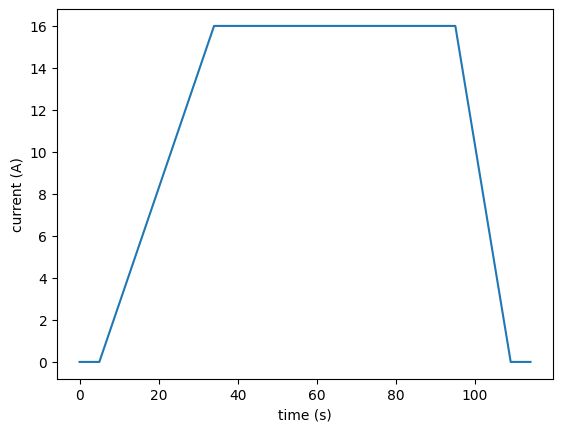

In [24]:
import matplotlib.pyplot as plt 

current = simulate_sessions()

plt.plot(current["current"])
plt.xlabel("time (s)")
plt.ylabel("current (A)")
plt.show()

In [25]:
# print Dataframe
print(current.head())

print(current.tail())

   current  time pilot_status status_charging  Voltage  power
0      0.0     0            B            idle        0    0.0
1      0.0     1            B            idle        0    0.0
2      0.0     2            B            idle        0    0.0
3      0.0     3            B            idle        0    0.0
4      0.0     4            B            idle        0    0.0
     current  time pilot_status status_charging  Voltage  power
110      0.0   110            B        complete        0    0.0
111      0.0   111            B        complete        0    0.0
112      0.0   112            B        complete        0    0.0
113      0.0   113            B        complete        0    0.0
114      0.0   114            B        complete        0    0.0
